In [1]:
import numpy as np
import pandas as pd
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score, accuracy_score, ConfusionMatrixDisplay, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [2]:
df = pd.read_parquet('../data/processed/abcd_first_msgs.parquet')
# df_sample = pd.read_json('../raw_data/abcd_sample.json')


In [3]:
df

,split,id,flow,subflow,first_msgs,refund,refund_label,n_words
0,train,3592,product_defect,return_size,"Hi! I need to return an item, can you help me ...",0,1,13
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10
2,train,3695,storewide_query,timing_4,HEY HO! I've got a promo code and I want to kn...,0,0,27
3,train,5798,shipping_issue,manage,"Hello, I would like to change my shipping deat...",0,1,18
4,train,3647,storewide_query,pricing_3,Hello. I have a really cool party coming up. A...,0,0,34
...,...,...,...,...,...,...,...,...
10037,test,1622,order_issue,manage_upgrade,HI I want to upgrade an order I have with you ...,0,0,14
10038,test,3293,manage_account,status_credit_missing,"Hi, I think I am missing a $40 credit from a s...",0,0,13
10039,test,8492,subscription_inquiry,manage_extension,I would like an extension on my subscription.,0,0,8
10040,test,189,storewide_query,pricing_1,Hi! How much do you charge to gift wrap items?,0,0,10


In [4]:


# stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor", "never", "give", "back"}
def clean_message(text):
    if pd.isna(text):
        return ""

    text = str(text).lower().strip()

    text = text.replace("’", "'")

    text = text.replace("won't", "will not")
    text = text.replace("can't", "can not")
    text = text.replace("n't", " not")
    text = text.replace("you're", "you are")


    text = re.sub(r"\bho!", " ", text)

    text = re.sub(
        r"^(hi+|hello+|helo+|hey+|hiya|good morning|heyo|"
        r"good afternoon|good evening)\b[\s,.!]*",
        "", text
    )

    text = re.sub(r"[^\w\s]|_", " ", text)
    text = re.sub(r"\s+", " ", text).strip()


    # words = [word for word in text.split() if word not in stop_words]

    return text.strip()

df["clean_text"] = df["first_msgs"].apply(clean_message)

display(df[["first_msgs", "clean_text"]].head(10))

,first_msgs,clean_text
0,"Hi! I need to return an item, can you help me ...",i need to return an item can you help me with ...
1,just wanted to check on the status of a refund,just wanted to check on the status of a refund
2,HEY HO! I've got a promo code and I want to kn...,i ve got a promo code and i want to know when ...
3,"Hello, I would like to change my shipping deat...",i would like to change my shipping deatails as...
4,Hello. I have a really cool party coming up. A...,i have a really cool party coming up and i nee...
5,I want an extension for my shopping service. I...,i want an extension for my shopping service i ...
6,"Hello, I am trying to check the status of my o...",i am trying to check the status of my order bu...
7,Hello I am trying to buy a pair of boots but t...,i am trying to buy a pair of boots but they ar...
8,I accidently ordered the wrong item and was wo...,i accidently ordered the wrong item and was wo...
9,I would like to confirm my address is correct ...,i would like to confirm my address is correct ...


In [5]:
df

,split,id,flow,subflow,first_msgs,refund,refund_label,n_words,clean_text
0,train,3592,product_defect,return_size,"Hi! I need to return an item, can you help me ...",0,1,13,i need to return an item can you help me with ...
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10,just wanted to check on the status of a refund
2,train,3695,storewide_query,timing_4,HEY HO! I've got a promo code and I want to kn...,0,0,27,i ve got a promo code and i want to know when ...
3,train,5798,shipping_issue,manage,"Hello, I would like to change my shipping deat...",0,1,18,i would like to change my shipping deatails as...
4,train,3647,storewide_query,pricing_3,Hello. I have a really cool party coming up. A...,0,0,34,i have a really cool party coming up and i nee...
...,...,...,...,...,...,...,...,...,...
10037,test,1622,order_issue,manage_upgrade,HI I want to upgrade an order I have with you ...,0,0,14,i want to upgrade an order i have with you to ...
10038,test,3293,manage_account,status_credit_missing,"Hi, I think I am missing a $40 credit from a s...",0,0,13,i think i am missing a 40 credit from a subscr...
10039,test,8492,subscription_inquiry,manage_extension,I would like an extension on my subscription.,0,0,8,i would like an extension on my subscription
10040,test,189,storewide_query,pricing_1,Hi! How much do you charge to gift wrap items?,0,0,10,how much do you charge to gift wrap items


In [6]:
# REFUND_SUBFLOWS = {
#     "refund_initiate",
#     "return_size",
#     "return_color",
#     "return_stain",
#     "manage_dispute_bill",
#     "bad_price_competitor",
#     "status_mystery_fee",
#     "refund_update",
#     "manage_cancel",
# }

# df["refund_request"] = df["subflow"].isin(REFUND_SUBFLOWS).astype(int)
# print(df["refund_request"].value_counts())

In [7]:
TARGET = "refund_label"

train = df[df["split"] == "train"]
val = df[df["split"] == "dev"]
test = df[df["split"] == "test"]

X_train = train["first_msgs"]
y_train = train[TARGET]

X_val = val["first_msgs"]
y_val = val[TARGET]

X_test = test["first_msgs"]
y_test = test[TARGET]

train_dev = df[df["split"].isin(["train", "dev"])]
X_td = train_dev["first_msgs"]
y_td = train_dev[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
print(y_train.value_counts(normalize=True))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_val)

print("accuracy:", accuracy_score(y_val, y_pred))
print("precision:", precision_score(y_val, y_pred, zero_division=0))
print("recall:", recall_score(y_val, y_pred))

refund_label
0    0.776948
1    0.223052
Name: proportion, dtype: float64
accuracy: 0.7719123505976095
precision: 0.0
recall: 0.0


In [9]:
models = {
    "count + none": make_pipeline(
        CountVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000),
    ),
    "count + none + ngrams": make_pipeline(
        CountVectorizer(preprocessor=clean_message, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000),
    ),
    "count + balanced": make_pipeline(
        CountVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + none": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000),
    ),
    "tfidf + balanced": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + balanced + ngrams": make_pipeline(
        TfidfVectorizer(preprocessor=clean_message, ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
}

In [10]:
# for name, pipe in models.items():
#     pipe.fit(X_train, y_train)
#     print(f"\n=== {name} ===")
#     print(classification_report(y_val, pipe.predict(X_val)))

In [11]:
# results = []

# for name, pipe in models.items():
#     pipe.fit(X_train, y_train)
#     y_pred = pipe.predict(X_val)

#     results.append({
#         "model": name,
#         "precision": precision_score(y_val, y_pred),
#         "recall": recall_score(y_val, y_pred),
#         "f1": f1_score(y_val, y_pred),
#         "f2_recall_weighs_more": fbeta_score(y_val, y_pred, beta=2),
#     })

# results_df = pd.DataFrame(results).sort_values("f2_recall_weighs_more", ascending=False)
# results_df


In [12]:
# best_name = results_df.iloc[0]["model"]
# best_model = models[best_name]

In [13]:
def plot_confusion(y_true, y_pred, title):
    """Confusion matrix with plain-language labels, counts and row percentages."""
    # Counts and row percentages (each row adds up to 100%)
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = confusion_matrix(y_true, y_pred, normalize="true")

    # Unpack the four cells: correct no, false alarm, missed, correct yes
    tn, fp, fn, tp = cm.ravel()
    tn_pct, fp_pct, fn_pct, tp_pct = cm_pct.ravel()

    # Text inside each cell, in the same layout as the grid
    labels = [
        [f"Correct: no refund intent\n{tn} ({tn_pct:.0%})", f"False alarm\n{fp} ({fp_pct:.0%})"],
        [f"Missed refund intent\n{fn} ({fn_pct:.0%})", f"Correct: refund intent\n{tp} ({tp_pct:.0%})"],
    ]

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm_pct,
        annot=labels,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=["Predicted: no refund", "Predicted: refund"],
        yticklabels=["Actually: no refund", "Actually: refund"],
    )
    plt.title(title)
    plt.show()

In [14]:
f2_scorer = make_scorer(fbeta_score, beta=2)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_td, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    cv_results.append({
        "model": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })
cv_results_df = pd.DataFrame(cv_results).sort_values("f2", ascending=False)
cv_best_name = cv_results_df.iloc[0]["model"]
print("Best model (CV):", cv_best_name)

cv_results_df

Best model (CV): tfidf + balanced + ngrams


,model,precision,recall,f2,f2_std
5,tfidf + balanced + ngrams,0.857563,0.903023,0.893371,0.010561
4,tfidf + balanced,0.811391,0.900544,0.881046,0.007909
2,count + balanced,0.823363,0.896086,0.880244,0.006344
1,count + none + ngrams,0.942419,0.844143,0.862087,0.009776
0,count + none,0.929509,0.833754,0.851192,0.016992
3,tfidf + none,0.946727,0.770416,0.800179,0.012279


In [15]:
td_probs = cross_val_predict(
    models[cv_best_name], X_td, y_td, cv=cv, method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in [0.35, 0.40, 0.42, 0.44, 0.46, 0.48, 0.50, 0.55]:
    y_pred = (td_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_td, y_pred),
        "recall": recall_score(y_td, y_pred),
        "f2": fbeta_score(y_td, y_pred, beta=2),
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,precision,recall,f2
0,0.35,0.709320,0.949035,0.888951
1,0.40,0.770740,0.933201,0.895452
2,0.42,0.793806,0.925779,0.895987
3,0.44,0.812473,0.921821,0.897658
4,0.46,0.827293,0.914894,0.895920
5,0.48,0.845517,0.909946,0.896286
6,0.50,0.856405,0.903018,0.893294
7,0.55,0.892177,0.880257,0.882616


In [16]:
FINAL_THRESHOLD = 0.44

precision: 0.7898832684824902
recall: 0.9269406392694064
f2: 0.8958517210944396


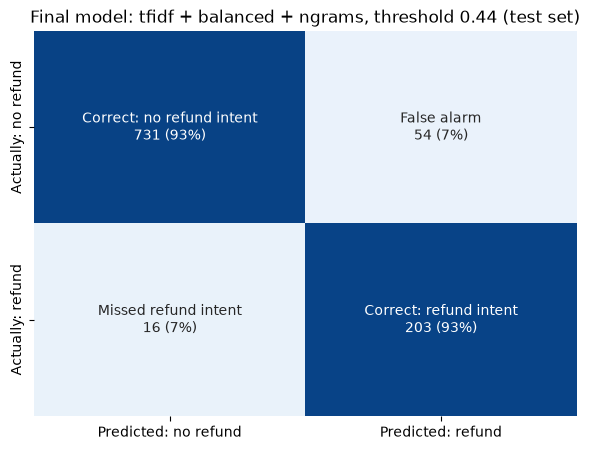

In [17]:
final_model = models[cv_best_name].fit(X_td, y_td)
test_probs = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_probs >= FINAL_THRESHOLD).astype(int)
print("precision:", precision_score(y_test, y_pred_test))
print("recall:", recall_score(y_test, y_pred_test))
print("f2:", fbeta_score(y_test, y_pred_test, beta=2))

plot_confusion(
    y_test,
    y_pred_test,
    f"Final model: {cv_best_name}, threshold {FINAL_THRESHOLD} (test set)",
)

In [18]:
prompts = [
    "I just want to talk to someone today",
    "hi! my jeans are too small, I want my money back",
    "where is my refund?",
    "can I change my delivery address?",
    "I bought some jeans but they dont fit"
]

for prompt in prompts:
    refund_prob = final_model.predict_proba([prompt])[0][1]
    print(f"Refund Intent: {refund_prob:.0%}  {prompt}")

Refund Intent: 26%  I just want to talk to someone today
Refund Intent: 46%  hi! my jeans are too small, I want my money back
Refund Intent: 87%  where is my refund?
Refund Intent: 42%  can I change my delivery address?
Refund Intent: 59%  I bought some jeans but they dont fit


In [19]:
# #check weights of words
# prompt_99 = "Hello! I bought these jeans. I want to return them for a different size and color."

# prompt = "I just want to talk to someone today"
# refund_prob = best_model.predict_proba([prompt])[0][1]
# print(f"Refund intent: {refund_prob:.0%}")

In [20]:
prompt_text = 'I recently purchased a skirt, but I realized I dont really wear those. I want my money back.'
test = clean_message(prompt_text)

print(test)

i recently purchased a skirt but i realized i dont really wear those i want my money back
